<a href="https://colab.research.google.com/github/miriamamin1213-ux/Ablation_studies/blob/main/HancockLR.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Mounted at /content/drive
Rows: 332 | 3-fold cross-validation across the entire eligible dataset
Class counts: {0: 191, 1: 141}


Fold 1/3 | balanced accuracy: 0.6991 | threshold: 0.505


Fold 2/3 | balanced accuracy: 0.7232 | threshold: 0.510


Fold 3/3 | balanced accuracy: 0.7342 | threshold: 0.590

FOLD METRICS
    Fold  Accuracy  Balanced_Accuracy  Precision    Recall        F1   ROC_AUC  \
0     1  0.711712           0.699136   0.674419  0.617021  0.644444  0.748836   
1     2  0.729730           0.723238   0.680851  0.680851  0.680851  0.741024   
2     3  0.763636           0.734211   0.862069  0.531915  0.657895  0.788078   

     PR_AUC  Threshold  
0  0.732961      0.505  
1  0.699897      0.510  
2  0.798101      0.590  

MEAN FOLD METRICS
 Accuracy             0.735026
Balanced_Accuracy    0.718862
Precision            0.739113
Recall               0.609929
F1                   0.661063
ROC_AUC              0.759313
PR_AUC               0.743653
Threshold            0.535000
dtype: float64

OOF METRICS
 Accuracy               0.734940
Balanced_Accuracy      0.718577
Precision              0.722689
Recall                 0.609929
F1                     0.661538
ROC_AUC                0.761464
PR_AUC                 

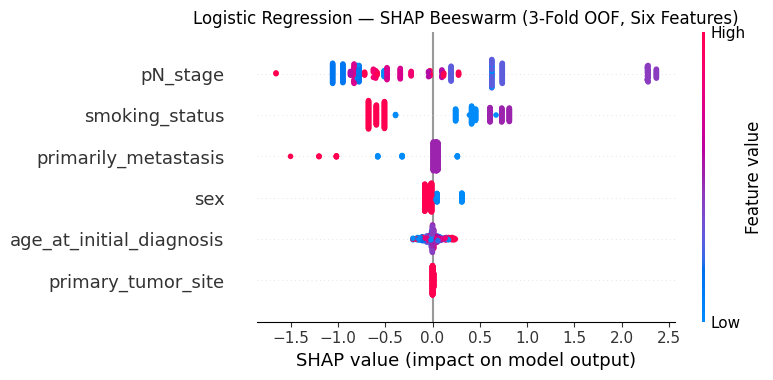

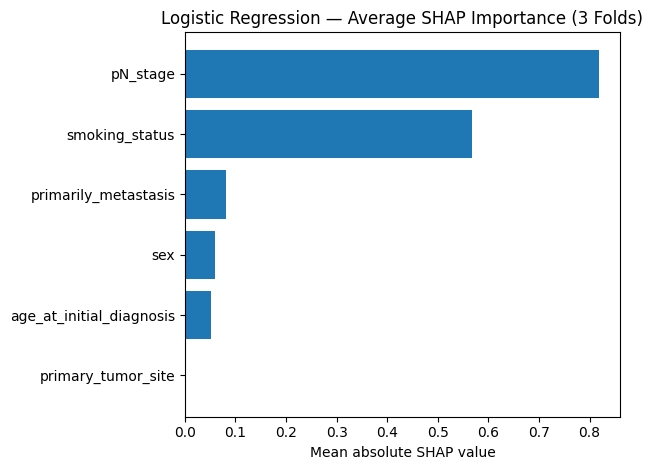

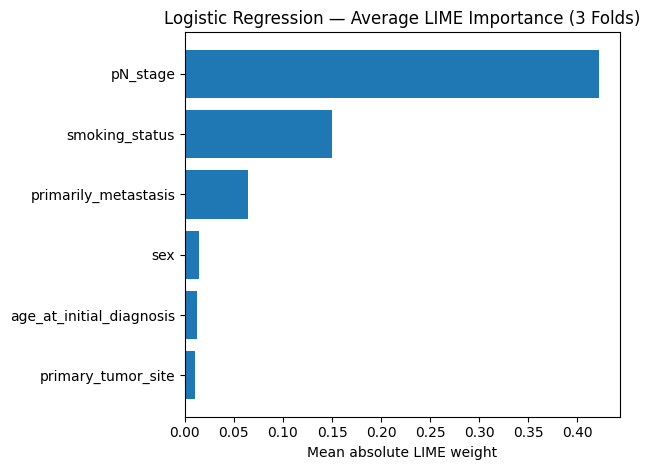

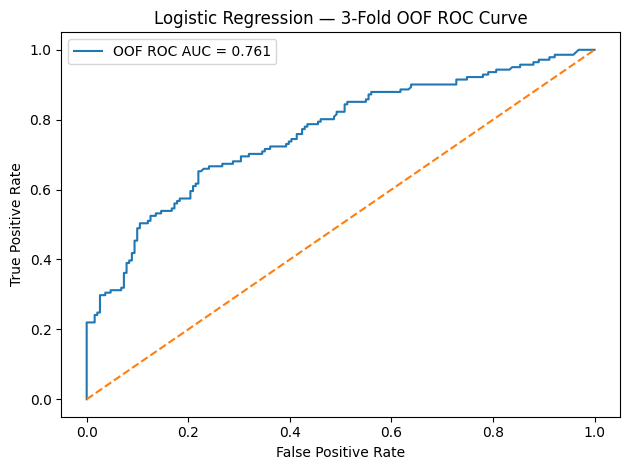

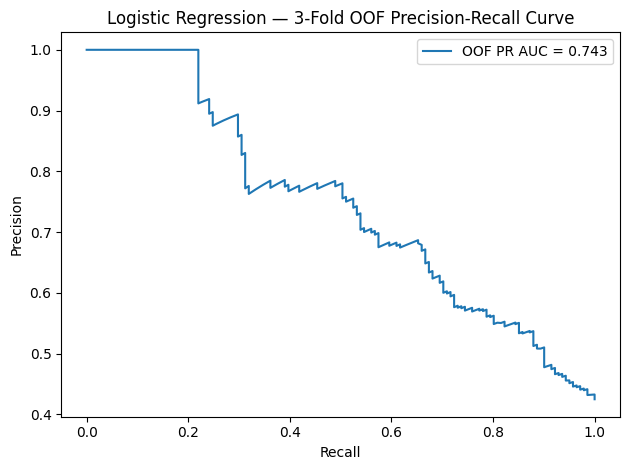

Saved results to: /content/drive/MyDrive/LR_results


In [1]:
# ============================================================
# LOGISTIC REGRESSION — HANCOCK HPV CLASSIFIER
# Shared data preparation | Seed 42 | No SMOTE
# ============================================================

import os, json, random, warnings, subprocess, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import drive
from sklearn.model_selection import StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
import shap
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, average_precision_score,
    confusion_matrix, classification_report, roc_curve,
    precision_recall_curve
)

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

drive.mount("/content/drive")

# ------------------------------------------------------------
# 1. LOAD AND PREPARE THE SAME DATA USED BY GPT-2
# ------------------------------------------------------------

BASE = "/content/drive/MyDrive"
OUT_DIR = os.path.join(BASE, "LR_results")
os.makedirs(OUT_DIR, exist_ok=True)

def load_json_table(path):
    with open(path, "r", encoding="utf-8") as f:
        obj = json.load(f)
    if isinstance(obj, list):
        return pd.DataFrame(obj)
    if isinstance(obj, dict):
        for key in ["data", "records", "patients", "items"]:
            if key in obj and isinstance(obj[key], list):
                return pd.DataFrame(obj[key])
        return pd.DataFrame(obj)
    raise ValueError(f"Cannot read table from {path}")

clinical = load_json_table(os.path.join(BASE, "clinical_data.json"))
pathology = load_json_table(os.path.join(BASE, "pathological_data.json"))

if "patient_id" not in clinical or "patient_id" not in pathology:
    raise KeyError("Both files must contain patient_id.")

df = clinical.merge(
    pathology, on="patient_id", how="left", suffixes=("", "_path")
)

target_candidates = ["hpv_association_p16", "hpv_association_p16_path"]
target_col = next((c for c in target_candidates if c in df.columns), None)
if target_col is None:
    raise KeyError(f"Target not found. Available columns: {df.columns.tolist()}")

feature_candidates = {
    "age_at_initial_diagnosis": ["age_at_initial_diagnosis"],
    "sex": ["sex"],
    "smoking_status": ["smoking_status"],
    "primary_tumor_site": ["primary_tumor_site"],
    "primarily_metastasis": ["primarily_metastasis"],
    "pN_stage": ["pN_stage", "pN_stage_path", "pathological_N_stage",
                 "pathologic_N_stage", "pathological_n_stage"]
}
resolved = {}
for name, candidates in feature_candidates.items():
    match = next((c for c in candidates if c in df.columns), None)
    if match is None:
        raise KeyError(f"Missing predictor {name}; checked {candidates}")
    resolved[name] = match

df = df.rename(columns={v: k for k, v in resolved.items() if v != k})
features = list(feature_candidates.keys())

def normalize_label(value):
    if pd.isna(value):
        return np.nan
    value = str(value).strip().lower()
    if value in {"negative", "neg", "0", "false", "no"}:
        return 0
    if value in {"positive", "pos", "1", "true", "yes"}:
        return 1
    try:
        number = float(value)
        if number in (0.0, 1.0):
            return int(number)
    except (ValueError, TypeError):
        pass
    return np.nan

df["HPV_Label"] = df[target_col].map(normalize_label)
df = df.dropna(subset=["HPV_Label"]).copy()
df["HPV_Label"] = df["HPV_Label"].astype(int)
df = df[["patient_id"] + features + ["HPV_Label"]].copy()

# Use all eligible patients in stratified 3-fold cross-validation.
print("Rows:", len(df), "| 3-fold cross-validation across the entire eligible dataset")
print("Class counts:", df["HPV_Label"].value_counts().sort_index().to_dict())
numeric_features = ["age_at_initial_diagnosis"]
categorical_features = [c for c in features if c not in numeric_features]

# ------------------------------------------------------------
# 2. THREE-FOLD TRAINING, THRESHOLD SELECTION, SHAP AND LIME
# ------------------------------------------------------------
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
fold_metrics, tuning_rows, shap_fold_importance, lime_fold_importance = [], [], [], []
shap_plot_values, shap_plot_features = [], []
oof_prob = np.zeros(len(df)); oof_pred = np.zeros(len(df), dtype=int); oof_fold = np.zeros(len(df), dtype=int)
for fold, (train_idx, val_idx) in enumerate(cv.split(df[features], df["HPV_Label"]), 1):
    train, val = df.iloc[train_idx].copy(), df.iloc[val_idx].copy()
    try:
        encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)
    preprocessor = ColumnTransformer([
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), numeric_features),
        ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", encoder)]), categorical_features)
    ])
    X_train = preprocessor.fit_transform(train[features]); X_val = preprocessor.transform(val[features])
    y_train = train["HPV_Label"].to_numpy(); y_val = val["HPV_Label"].to_numpy()
    model = LogisticRegression(class_weight="balanced", max_iter=2000, random_state=SEED)
    model.fit(X_train, y_train)
    val_prob = model.predict_proba(X_val)[:, 1]
    thresholds = np.linspace(0.10, 0.90, 161)
    scores = [balanced_accuracy_score(y_val, (val_prob >= t).astype(int)) for t in thresholds]
    best_score = max(scores)
    best_threshold = min((t for t, s in zip(thresholds, scores) if s == best_score), key=lambda t: abs(t - 0.5))
    val_pred = (val_prob >= best_threshold).astype(int)
    oof_prob[val_idx] = val_prob; oof_pred[val_idx] = val_pred; oof_fold[val_idx] = fold
    fold_result = {
        "Fold": fold, "Accuracy": accuracy_score(y_val, val_pred),
        "Balanced_Accuracy": balanced_accuracy_score(y_val, val_pred),
        "Precision": precision_score(y_val, val_pred, zero_division=0),
        "Recall": recall_score(y_val, val_pred, zero_division=0),
        "F1": f1_score(y_val, val_pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_val, val_prob) if len(np.unique(y_val)) == 2 else np.nan,
        "PR_AUC": average_precision_score(y_val, val_prob), "Threshold": float(best_threshold)
    }
    fold_metrics.append(fold_result)
    tuning_rows.append({"fold": fold, "validation_balanced_accuracy": best_score, "threshold": float(best_threshold)})
    names = list(preprocessor.get_feature_names_out())
    groups = {}
    for i, name in enumerate(names):
        clean = name.split("__", 1)[-1]
        original = next((f for f in sorted(features, key=len, reverse=True) if clean == f or clean.startswith(f + "_")), clean)
        groups.setdefault(original, []).append(i)
    # Sum one-hot SHAP contributions back to the six original predictors.
    try:
        explainer = shap.LinearExplainer(model, X_train)
        fold_shap = explainer.shap_values(X_val)
    except Exception:
        explainer = shap.Explainer(model, X_train)
        fold_shap = explainer(X_val).values
    if isinstance(fold_shap, list):
        fold_shap = fold_shap[1] if len(fold_shap) > 1 else fold_shap[0]
    fold_shap = np.asarray(fold_shap)
    if fold_shap.ndim == 3:
        fold_shap = fold_shap[:, :, 1] if fold_shap.shape[-1] == 2 else fold_shap[1]
    grouped_shap = np.column_stack([fold_shap[:, groups.get(f, [])].sum(axis=1) if groups.get(f) else np.zeros(len(val)) for f in features])
    shap_fold_importance.append(np.abs(grouped_shap).mean(axis=0))
    shap_plot_values.append(pd.DataFrame(grouped_shap, columns=features))
    display_values = pd.DataFrame(index=val.index)
    for feature in features:
        if feature in numeric_features:
            display_values[feature] = pd.to_numeric(val[feature], errors="coerce")
        else:
            categories = sorted(df[feature].fillna("Missing").astype(str).unique())
            display_values[feature] = pd.Categorical(val[feature].fillna("Missing").astype(str), categories=categories).codes.astype(float)
    shap_plot_features.append(display_values.reset_index(drop=True))
    # Aggregate absolute LIME weights by the same six original predictors.
    try:
        from lime.lime_tabular import LimeTabularExplainer
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "lime"])
        from lime.lime_tabular import LimeTabularExplainer
    lime_explainer = LimeTabularExplainer(X_train, feature_names=names, class_names=["Negative", "Positive"], mode="classification", discretize_continuous=False, random_state=SEED)
    lime_values = np.zeros(len(features)); lime_count = min(100, len(X_val))
    for row in X_val[:lime_count]:
        explanation = lime_explainer.explain_instance(row, model.predict_proba, num_features=len(names), labels=(1,))
        for index, weight in explanation.as_map().get(1, []):
            for j, feature in enumerate(features):
                if index in groups.get(feature, []):
                    lime_values[j] += abs(weight); break
    lime_fold_importance.append(lime_values / max(lime_count, 1))
    print(f"Fold {fold}/3 | balanced accuracy: {fold_result['Balanced_Accuracy']:.4f} | threshold: {best_threshold:.3f}")
# ------------------------------------------------------------
# 3. THREE-FOLD EVALUATION AND SAVE OUTPUTS
# ------------------------------------------------------------
metrics = {
    "Accuracy": accuracy_score(df["HPV_Label"], oof_pred),
    "Balanced_Accuracy": balanced_accuracy_score(df["HPV_Label"], oof_pred),
    "Precision": precision_score(df["HPV_Label"], oof_pred, zero_division=0),
    "Recall": recall_score(df["HPV_Label"], oof_pred, zero_division=0),
    "F1": f1_score(df["HPV_Label"], oof_pred, zero_division=0),
    "ROC_AUC": roc_auc_score(df["HPV_Label"], oof_prob) if df["HPV_Label"].nunique() == 2 else np.nan,
    "PR_AUC": average_precision_score(df["HPV_Label"], oof_prob),
    "Mean_Fold_Threshold": float(np.mean([m["Threshold"] for m in fold_metrics]))
}
fold_metrics_df = pd.DataFrame(fold_metrics)
print("\nFOLD METRICS\n", fold_metrics_df)
print("\nMEAN FOLD METRICS\n", fold_metrics_df.drop(columns="Fold").mean(numeric_only=True))
print("\nOOF METRICS\n", pd.Series(metrics))
print("\nConfusion matrix:\n", confusion_matrix(df["HPV_Label"], oof_pred))
print("\nClassification report:\n", classification_report(df["HPV_Label"], oof_pred, zero_division=0))
fold_metrics_df.to_csv(os.path.join(OUT_DIR, "fold_metrics.csv"), index=False)
pd.DataFrame(tuning_rows).to_csv(os.path.join(OUT_DIR, "validation_tuning.csv"), index=False)
pd.DataFrame([metrics]).to_csv(os.path.join(OUT_DIR, "metrics.csv"), index=False)
pd.DataFrame({"patient_id": df["patient_id"].to_numpy(), "y_true": df["HPV_Label"].to_numpy(), "probability_positive": oof_prob, "prediction": oof_pred, "fold": oof_fold}).to_csv(os.path.join(OUT_DIR, "oof_predictions.csv"), index=False)
# Average SHAP importance and beeswarm, grouped to exactly six original predictors.
mean_shap = np.mean(shap_fold_importance, axis=0)
shap_df = pd.DataFrame({"feature": features, "mean_abs_shap": mean_shap}).sort_values("mean_abs_shap", ascending=False)
shap_df.to_csv(os.path.join(OUT_DIR, "shap_average.csv"), index=False)
shap_all = pd.concat(shap_plot_values, ignore_index=True)
X_all = pd.concat(shap_plot_features, ignore_index=True)[features]
plt.figure()
shap.summary_plot(shap_all.to_numpy(), X_all, feature_names=features, plot_type="dot", max_display=len(features), show=False)
plt.title("Logistic Regression — SHAP Beeswarm (3-Fold OOF, Six Features)")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "shap_beeswarm.png"), dpi=150, bbox_inches="tight"); plt.show(); plt.close()
plt.figure()
plt.barh(shap_df["feature"][::-1], shap_df["mean_abs_shap"][::-1])
plt.xlabel("Mean absolute SHAP value"); plt.title("Logistic Regression — Average SHAP Importance (3 Folds)")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "shap_average.png"), dpi=150, bbox_inches="tight"); plt.show(); plt.close()
# Average LIME importance across folds, grouped to the same six original predictors.
mean_lime = np.mean(lime_fold_importance, axis=0)
lime_df = pd.DataFrame({"feature": features, "mean_abs_lime_weight": mean_lime}).sort_values("mean_abs_lime_weight", ascending=False)
lime_df.to_csv(os.path.join(OUT_DIR, "lime_average.csv"), index=False)
plt.figure()
plt.barh(lime_df["feature"][::-1], lime_df["mean_abs_lime_weight"][::-1])
plt.xlabel("Mean absolute LIME weight"); plt.title("Logistic Regression — Average LIME Importance (3 Folds)")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "lime_average.png"), dpi=150, bbox_inches="tight"); plt.show(); plt.close()
with open(os.path.join(OUT_DIR, "settings.json"), "w") as f:
    json.dump({"model": "Logistic Regression", "seed": SEED, "features": features, "target_column": target_col, "cross_validation": "StratifiedKFold", "n_splits": 3, "dataset_rows": len(df), "class_weight": "balanced", "smote": False, "fold_metrics": fold_metrics}, f, indent=2, default=str)
if len(np.unique(df["HPV_Label"])) == 2:
    fpr, tpr, _ = roc_curve(df["HPV_Label"], oof_prob)
    plt.figure()
    plt.plot(fpr, tpr, label=f"OOF ROC AUC = {metrics['ROC_AUC']:.3f}")
    plt.plot([0, 1], [0, 1], "--")
    plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
    plt.title("Logistic Regression — 3-Fold OOF ROC Curve"); plt.legend(); plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, "roc_curve.png"), dpi=150); plt.show()
    precision, recall, _ = precision_recall_curve(df["HPV_Label"], oof_prob)
    plt.figure()
    plt.plot(recall, precision, label=f"OOF PR AUC = {metrics['PR_AUC']:.3f}")
    plt.xlabel("Recall"); plt.ylabel("Precision")
    plt.title("Logistic Regression — 3-Fold OOF Precision-Recall Curve"); plt.legend(); plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, "pr_curve.png"), dpi=150); plt.show()
print("Saved results to:", OUT_DIR)

